# Airfoil Co-Kriging

Load the NACA airfoil coordinates and predict. The coordinates should be arranged in one sense. Meaning, that `XB` and `YB` are either in a clockwise or anti-clockwise arrangement. 

## Exact solution

The true velocity is computed using the BEM code. 
GRID discretization used:    

```{python}
# Grid parameters
nGridX   = 30                                                             # X-grid for streamlines and contours
nGridY   = 30                                                             # Y-grid for streamlines and contours
xVals    = [min(XB)-0.5, max(XB)+0.5]                                     # X-grid extents [min, max]
yVals    = [min(YB)-0.2, max(YB)+0.2]                                     # Y-grid extents [min, max]
```

In [66]:
# imports 
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, Point
# from scipy.interpolate import griddata
from matrices import CovM, CovFn, Umat
from covderivatives2D import AnalyticalSqExpdiff2D
from calibration import LOOMSECK2D, LOOVARCK2D, adamopt, Adam
import matplotlib.cm as cm
from matplotlib.colors import Normalize

In [67]:
# Image path to save the images.
IMGPATH = r'IMAGES/' 

# load the NACA airfoil data
NACAname = r'2424'
XB, YB, nX, nY = np.loadtxt('data/NACA'+NACAname+'UIUCnormalvecs.dat', 
                            unpack=True)
XX, YY, Vx, Vy = np.loadtxt('data/NACA'+NACAname+'BEMflow.dat',
                            unpack=True)

In [ ]:
# TEST : normal vectors visualization. 
# plt.quiver(XX, YY, Vx, Vy)
# plt.plot(XB, YB)
# for _ in range(XB.shape[0]):
#     plt.plot([XB[_], XB[_] + 0.05*nX[_]], 
#              [YB[_], YB[_] + 0.05*nY[_]], c = 'red')
# # plt.ylim(-0.75, 0.75)                     # Smaller scale makes the normal vectors more apparent.
# plt.show()

In [ ]:

# TEST : choice of observation locations
# Vx[XX == min(XX)]
# nLobs = 10;
# nMobs = 2
# step = int(30/nLobs)
# plt.quiver(XX, YY, Vx, Vy)
# plt.scatter(XX[XX==min(XX)][::step], YY[XX==min(XX)][::step],  
#             s = 10, c = 'red', marker = 'x')
# plt.scatter(XX[XX==max(XX)][::step], YY[XX==max(XX)][::step],  
#             s = 10, c = 'red', marker = 'x')
# plt.scatter(XX[YY==min(YY)][int(30/nMobs)::int(30/nMobs)], YY[YY==min(YY)][int(30/nMobs)::int(30/nMobs)],  
#             s = 10, c = 'red', marker = 'x')
# plt.scatter(XX[YY==max(YY)][int(30/nMobs)::int(30/nMobs)], YY[YY==max(YY)][int(30/nMobs)::int(30/nMobs)],  
#             s = 10, c = 'red', marker = 'x')
# plt.fill(XB, YB)

In [ ]:
# TEST : obtain continuity collocation points
# nc = 10;                                               # Discretization to choose collocation points.
# airfoilshape = Polygon(np.column_stack([XB, YB]))      # Defining a polygon based on the airfoil profile.
# xgrid = np.linspace(min(XX)-0.1,max(XX)+0.1,nc)                
# ygrid = np.linspace(min(YY)-0.1,max(YY)+0.1,nc)
# xgrid, ygrid = np.meshgrid(xgrid, ygrid)               # raw grid of points.
# airfoilcontains = lambda x, y: airfoilshape.contains(Point(x, y))   # Function to check if point is within airfoil. 
# withinairfoil = np.array(list(map(airfoilcontains, 
#                                 xgrid.flatten(), 
#                                 ygrid.flatten())))
# Cx = xgrid.flatten()[~withinairfoil]       # retaining only the points outside the airfoil, x-coordinates
# Cy = ygrid.flatten()[~withinairfoil]       # retaining only the points outside the airfoil, y-coordinates
# plt.scatter(Cx, Cy, marker = 'x', s = 10)
# plt.plot(XB, YB)
# plt.show()

## Defining relevant points in the extended design space.
 - Observation points (`Obs`). $v_x \rightarrow$ `m = (1,0)`. $v_y \rightarrow$ `m = (0,1)`.
 - Continuity collocation points (`C`). $\phi_{xx}\rightarrow$ `m = (2,0)`. $\phi_{yy}\rightarrow$ `m = (0,2)` 
 - Boundary collocation points (`B`). `m = (1,0)` \& `m = (0,1)`.
 - Prediction points (`Pred`). `m = (1,0)` \& `m = (0,1)`.
 

In [68]:
# USER INPUTS
## Observation locations with derivative orders.
nobs = 20                                  # number of observations (at inf. on each side)
nm = 20                                    # number of observations in the middle of the domain.
nc = 5                                     # discretization for continuity collocation points.
nb = 30                                    # discretization for boundary collocation points. nb = 50 for NACA0012, nb = 30 for NACA4412, NACA2424.
UQFLAG = 1                                 # For uncertainty prediction
ostep = int(np.sqrt(XX.shape[0])/nobs)     # step size to select observation points at infinity.
mstep = int(np.sqrt(XX.shape[0])/nm)       # step size to select observation points in the domain.
bstep = int(XB.shape[0]/nb)                # step size to select boundary points.

In [69]:
# Observation locations
mask = np.zeros_like(XX, dtype = bool)      # mask to choose the right observation indices.

for _ in np.where(XX==min(XX))[0][::ostep]:
    mask[_] = True;                         # observations at -infinity.
for _ in np.where(XX==max(XX))[0][::ostep]:
    mask[_] = True;                         # observations at +infinity.
for _ in np.where(YY==min(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (upper) mid-domain observations (avoiding redundancy)
for _ in np.where(YY==max(YY))[0][mstep::mstep]:
    mask[_] = True;                         # (lower) mid-domain observations (avoiding redundancy)

nobs = np.sum(mask)                         # redefining nobs based on the chosen locations.
Obs = np.zeros((2*nobs, 2, 2))              # Observations of [Vx, Vy].

## Setting the appropriate locations. 
Obs[:nobs, 0, 0] = XX[mask]; 
Obs[:nobs, 0, 1] = YY[mask] 
Obs[nobs:, 0, :] = Obs[:nobs, 0, :]         # repeating the same observation locations.

## Setting the right order of derivatives. 
Obs[:nobs, 1, 0] = 1; Obs[nobs:, 1, 1] = 1  # m = (1,0) and m = (0,1) 

@David's experiment. Random observations instead of a uniform grid.

Conclusion: Doesn't give that good results. The effect of few observations is that there is a lot of domain entry-exit behaviour (stochastic). Random or uniform grid barely makes a difference in that context. 

In [ ]:
# To use random observations at infinity instead of a uniform gird of observations. 
# Observation locations
# mask = np.zeros_like(XX, dtype = bool)      # mask to choose the right observation indices.

# for _ in np.random.choice(np.where(XX==min(XX))[0], nobs):
#     mask[_] = True;                         # observations at -infinity.
# for _ in np.random.choice(np.where(XX==max(XX))[0], nobs):
#     mask[_] = True;                         # observations at +infinity.
# for _ in np.random.choice(np.where(YY==min(YY))[0], nm):
#     mask[_] = True;                         # (upper) mid-domain observations (avoiding redundancy)
# for _ in np.random.choice(np.where(YY==max(YY))[0], nm):
#     mask[_] = True;                         # (lower) mid-domain observations (avoiding redundancy)

# nobs = np.sum(mask)                         # redefining nobs based on the chosen locations.
# Obs = np.zeros((2*nobs, 2, 2))              # Observations of [Vx, Vy].

# ## Setting the appropriate locations. 
# Obs[:nobs, 0, 0] = XX[mask]; 
# Obs[:nobs, 0, 1] = YY[mask] 
# Obs[nobs:, 0, :] = Obs[:nobs, 0, :]         # repeating the same observation locations.

# ## Setting the right order of derivatives. 
# Obs[:nobs, 1, 0] = 1; Obs[nobs:, 1, 1] = 1  # m = (1,0) and m = (0,1) 

In [ ]:
# TEST : Is the `mask` vector properly defined?
# plt.scatter(XX[mask], YY[mask], marker = 'x')
# plt.quiver(XX[mask], YY[mask],
#            Vx[mask], Vy[mask])
# plt.show() 

when choosing continuity collocation points, set the discretization based on the scale of the x-axis and y-axis. The discretization in our implemention differs by a factor of four which we found as, 
```{python}
# setting the discretization to be representative of the scale on x-axis and y-axis
nc = 5                                                                      # A particular constant. Discretization on both axes is a multiple of `nc`.
rxy = (max(XX) - min(XX))/(max(YY) - min(YY))                               # ratio of the scale on x-axis and y-axis. 
nX = rxy * nc                                                               # WLOG, assuming the x-scale is higher. 
nY = nc         
```

In [70]:
# continuity collocation points
airfoilshape = Polygon(np.column_stack([XB, YB]))   # Defining a polygon based on the airfoil profile.
# discretization on x and y axis is chosen as nY/nX = range(Y)/range(X) 
xgrid = np.linspace(min(XX),max(XX),4*nc)           # collocation coordinates the prediction locations.              
ygrid = np.linspace(min(YY),max(YY),nc)
xgrid, ygrid = np.meshgrid(xgrid, ygrid)            # raw grid of points.
airfoilcontains = lambda x, y: airfoilshape.contains(Point(x, y))   # Function to check if point is within airfoil. 
withinairfoil = np.array(list(map(airfoilcontains, 
                                xgrid.flatten(), 
                                ygrid.flatten())))
Cx = xgrid.flatten()[~withinairfoil]                # retaining only the points outside the airfoil, x-coordinates
Cy = ygrid.flatten()[~withinairfoil]                # retaining only the points outside the airfoil, y-coordinates
p1 = Cx.shape[0]                                    # number of collocation locations
C = np.zeros((2*p1, 2, 2))                          # initializing the collocation points.

# Setting the locations
C[::2, 0, 0] = Cx; C[::2, 0, 1] = Cy                
C[1::2, 0, :] = C[::2, 0, :]                        # locations repeating twice.

# Setting the right order of derivatives.
C[::2, 1, 0] = 2; C[1::2, 1, 1] = 2                 # m = (2,0) & m = (0,2)

In [ ]:
# TEST : Are the continuity collocation points correct?
# plt.scatter(C[::2, 0, 0], C[1::2, 0, 1], marker = 'x', s = 10)
# plt.plot(XB, YB)
# plt.show()

In [71]:
# boundary collocation points
Bx = XB[::bstep]; By = YB[::bstep]                  # chosen boundary coordinates.
p2 = Bx.shape[0]                                    # NUM of collocation points. 
B = np.zeros((2*p2, 2, 2))                          # initialize: sparse subset of the boundary points.
B[::2, 0, 0] = Bx; B[::2, 0, 1] = By
B[1::2, 0, :] = B[::2, 0, :]                        # locations repeating twice.
B[::2, 1, 0] = 1; B[1::2, 1, 1] = 1                 # m = (1,0) & m = (0,1)

# normal vectors
nvects = np.column_stack([nX[::bstep], nY[::bstep]])

In [ ]:
# TEST : Are the boundary locations sensible? 
# plt.scatter(B[::2, 0, 0], B[1::2, 0, 1], marker = 'x', s = 20, c = 'r')
# plt.plot(XB, YB)
# plt.show()

# TEST : Are the normal vectors summing to 1.0
# print(nvects[:,0]**2 + nvects[:,1]**2)

In [72]:
# prediction points
q = XX.shape[0]                      # NUM prediction points.
Pred = np.zeros((2*q, 2, 2))         # initialize the prediction locations. 

# Setting the right locations.
Pred[:q, 0, :] = np.column_stack([XX, YY])
Pred[q:, 0, :] = Pred[:q, 0, :]

# Setting the right order of derivatives. 
Pred[:q, 1, 0] = 1                        # m = (1,0)
Pred[q:, 1, 1] = 1                        # m = (0,1)

# creating a mask to set predictions inside the airfoil to zero.
withinairfoil = np.array(list(map(airfoilcontains, 
                                    XX, 
                                    YY)))

In [ ]:
# TEST : Are the prediction locations correct? 
# plt.scatter(Pred[:q, 0, 0][~withinairfoil], 
#             Pred[q:, 0, 1][~withinairfoil], marker = 'x')
# plt.plot(XB, YB)
# plt.show()

## Kernel hyperparameters and covariance matrices
Set the variables `sigma` and `theta` to construct the covariance matrices OR opt for LOOCV hyperparameter tuning by setting `hypropt=1`.

In [73]:
# USER INPUTS
hypropt = 1;                                    # Flag to perform LOOCV hyperparameter tuning
sigma = 1.0;                                    # Default noise variance
theta = 1.0;                                    # Default lengthscale / correlation parameter.  

# Exact observations
v1, v2 = np.zeros(p1), np.zeros(p2)             # RHS of DiffEqns
n = Obs.shape[0]                                # True velocity observations.
ytrue = np.zeros(n + p1 + p2)                   # Full vector of observations.
ytrue[:int(n/2)] = Vx[mask];                    # vx obs first and then vy obs.
ytrue[int(n/2):n] = Vy[mask];
ytrue[n:n+p1] = v1                              # Laplacian = 0
ytrue[n+p1:] = v2                               # normal component  = 0

# Matrix U (coefficients for both differential equations)
U1 = Umat([1, 1], p1)                           # Laplacian coefficients. 
U2 = Umat(nvects, p2)                           # normal vector components. 

# Matrix K^+
def Kmatfn(params):
    CovParam = lambda *Z: CovM(*Z, kernel=AnalyticalSqExpdiff2D, **params)
    K11 = CovParam(Obs);                        # Block matrix structure
    K12 = CovParam(Obs, C) @ U1; K21 = K12.T                 
    K13 = CovParam(Obs, B) @ U2; K31 = K13.T
    K22 = U1.T @ CovParam(C) @ U1
    K23 = U1.T @ CovParam(C, B) @ U2; K32 = K23.T
    K33 = U2.T @ CovParam(B) @ U2
    Kplus = np.block([[K11, K12, K13],
                      [K21, K22, K23],
                      [K31, K32, K33]])
    return Kplus

Iter 1/100 - LOOMSE: 0.000   lengthscale: 0.107
Iter 2/100 - LOOMSE: 0.000   lengthscale: 0.117
Iter 3/100 - LOOMSE: 0.000   lengthscale: 0.122
Iter 4/100 - LOOMSE: 0.000   lengthscale: 0.126
Iter 5/100 - LOOMSE: 0.000   lengthscale: 0.131
Iter 6/100 - LOOMSE: 0.000   lengthscale: 0.135
Iter 7/100 - LOOMSE: 0.000   lengthscale: 0.138
Iter 8/100 - LOOMSE: 0.000   lengthscale: 0.141
Iter 9/100 - LOOMSE: 0.000   lengthscale: 0.144
Iter 10/100 - LOOMSE: 0.000   lengthscale: 0.146
Iter 11/100 - LOOMSE: 0.000   lengthscale: 0.148
Iter 12/100 - LOOMSE: 0.000   lengthscale: 0.149
Iter 13/100 - LOOMSE: 0.000   lengthscale: 0.151
Iter 14/100 - LOOMSE: 0.000   lengthscale: 0.153
Iter 15/100 - LOOMSE: 0.000   lengthscale: 0.154
Iter 16/100 - LOOMSE: 0.000   lengthscale: 0.156
Iter 17/100 - LOOMSE: 0.000   lengthscale: 0.158
Iter 18/100 - LOOMSE: 0.000   lengthscale: 0.161
Iter 19/100 - LOOMSE: 0.000   lengthscale: 0.164
Iter 20/100 - LOOMSE: 0.000   lengthscale: 0.166
Iter 21/100 - LOOMSE: 0.000  

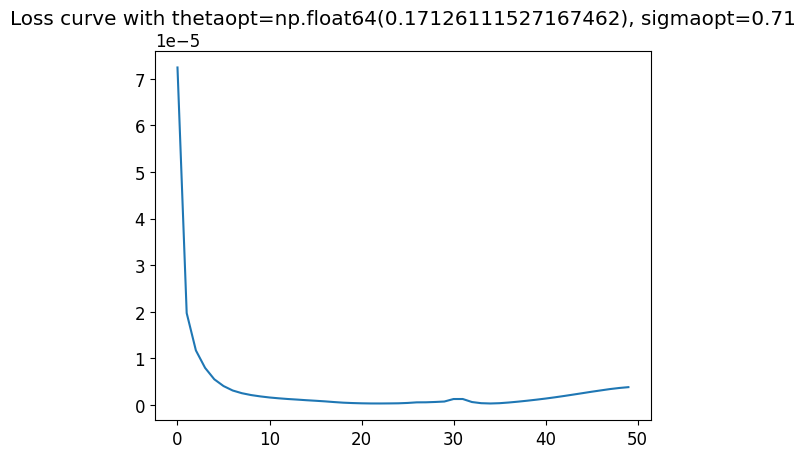

In [74]:
##########################
# LOOCV optimization step
##########################
if hypropt == 1:
    bL = 0.1; bR = 0.3                                  # left and right bounds
    bounds = [bL, bR]                                   # To initialize theta (correlation parameter)
    n_iter = 100
    loomsefn = lambda theta: LOOMSECK2D(theta, ytrue, n, Kmatfn, sigma = 1.0)
    thetaopt, optscore, history = adamopt(loomsefn, bounds, n_iter = n_iter, stoploss = 50) # For a shorter implementation, try with stoploss = 10.
    print(f'{thetaopt=}'); print(f'{optscore=:.4f}')
    sigmaopt = LOOVARCK2D(ytrue, n, Kmatfn, dict(theta = thetaopt,
                                                sigma = 1.0), nugget = 1e-6)
    print(f'{sigmaopt=:.2f}')
    plt.figure()
    if not np.sum(history==1e10) == 0:                  # To check IF the stopping criterion was invoked
        stopindex = int(np.where(history==1e10)[0][0])  # WHERE the stopping criteria was invoked
        plt.plot(range(stopindex - 1), history[:stopindex-1]); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
    else: 
        plt.plot(range(n_iter), history); plt.title(f'Loss curve with {thetaopt=}, {sigmaopt=:.2f}')
    # plt.savefig(IMGPATH + 'lossAirfoilCK.pdf')
    # plt.show()      # To visualize LOOCV loss curve
else: 
    print(f'Using the fixed kernel params (user inputs): {theta=}, {sigma=:.2f}')
    thetaopt = theta; 
    sigmaopt = LOOVARCK2D(ytrue, n, Kmatfn, dict(theta = thetaopt,
                                                    sigma = 1.0), nugget = 1e-6)


## Final predictions and UQ

In [75]:
## Matrix K^+ (optimal)
Kplus = Kmatfn(dict(theta = thetaopt,                       # LOOCV Optimal Kplus matrix 
                     sigma = 1.0)) 

## Matrix H^+
params = dict(theta = thetaopt, sigma = 1.0)
CovParam = lambda *Zvals: CovM(*Zvals, kernel = AnalyticalSqExpdiff2D, **params)
PredOut = np.vstack([Pred[:q][~withinairfoil],              # vx outside airfoil
                     Pred[q:][~withinairfoil]])             # vy outside airfoil
H1 = CovParam(Obs, PredOut)
H2 = U1.T @ CovParam(C, PredOut)
H3 = U2.T @ CovParam(B, PredOut)
Hplus = np.block([[H1], 
                  [H2], 
                  [H3]])

In [81]:
# Simple co-Kriging [yhat]
# yhat = np.zeros(2*q)                                       # Prediction of [Vx, Vy]
qout = int(PredOut.shape[0]/2)
nugget = 1e-1                                                # small nugget for numerical stability.
I = np.eye(Kplus.shape[0]); nI = nugget * I
Kplusinv = np.linalg.solve(Kplus + nI, I)
vxhat, vyhat = (Hplus.T @ Kplusinv @ ytrue).reshape(2, qout)
# yhat = Hplus.T @ Kplusinv @ ytrue

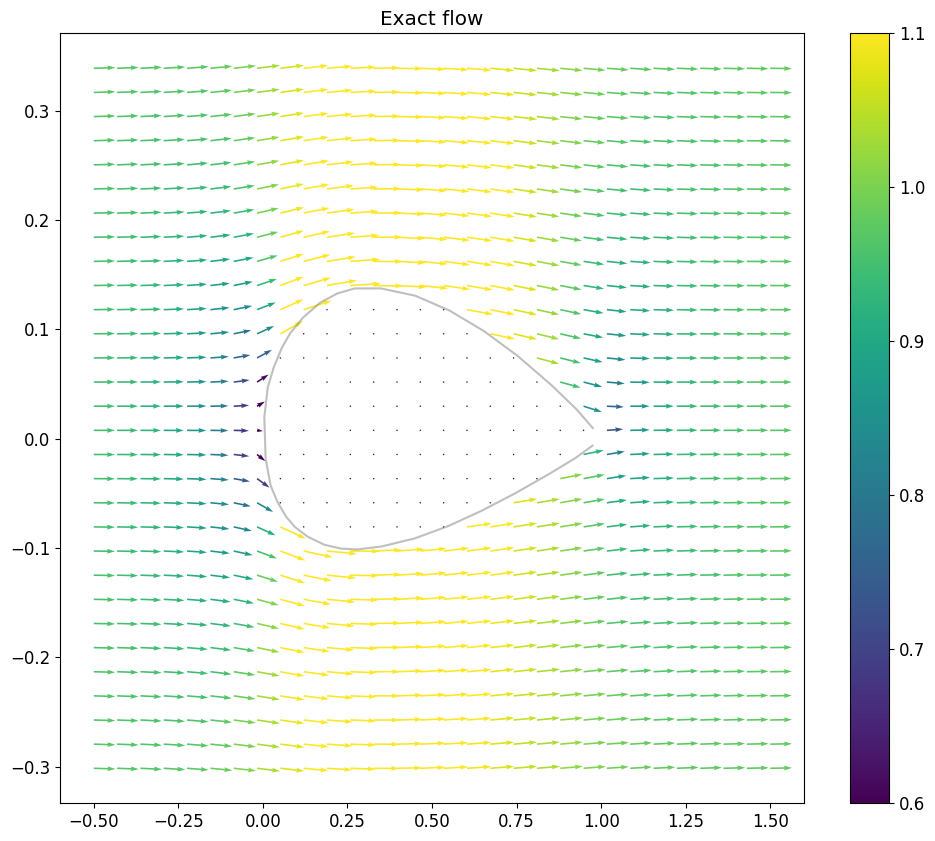

In [77]:
## Visualization true flow
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})    
widf = 1.5
plt.figure(figsize = (12, 10))
plt.cla()
quiverkwargs = dict(pivot = 'tail',
                    scale = 1/0.030, 
                    width = 3.25/(widf*1e3), 
                    clim = (0.6, 1.1))                                  # Colorbar
Q1 = plt.quiver(XX, YY,
                Vx, Vy,
                np.hypot(Vx, Vy), 
                alpha = 1,
                **quiverkwargs) 
plt.colorbar()
plt.plot(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Exact flow')
# plt.xlim(-1,2)
# plt.ylim(-1.4, 1.4)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

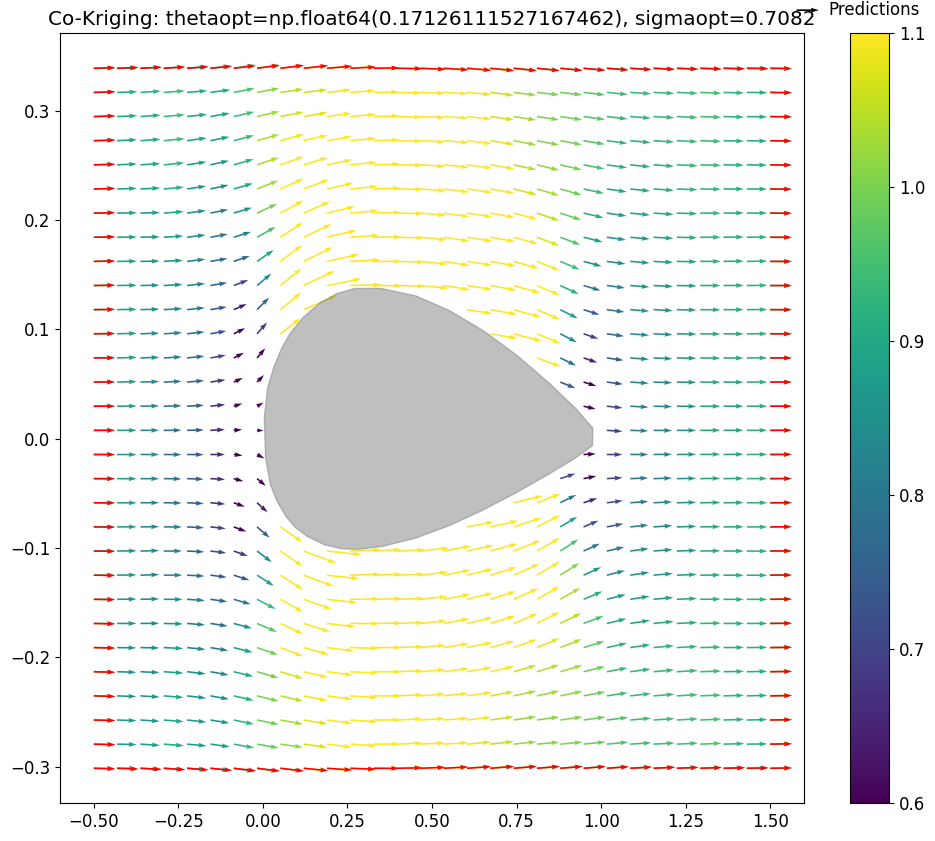

In [82]:
## Visualization Co-Kriging flow prediction
plt.figure(figsize = (12, 10))
plt.cla()
Q2 = plt.quiver(PredOut[:qout, 0, 0], PredOut[:qout, 0, 1],
                vxhat, vyhat,
                np.hypot(vxhat, vyhat), 
                alpha = 1.0,
                **quiverkwargs)
plt.colorbar()
Q1 = plt.quiver(XX[mask], YY[mask],
                Vx[mask], Vy[mask],
                color = 'red', alpha = 1,
                **quiverkwargs) 
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
plt.fill(XB, YB,
         alpha = 0.5, c = 'grey', label='Obstacle')
plt.title(f'Co-Kriging: {thetaopt=}, {sigmaopt=:.4f}')
# plt.xlim(min(XX)-0.05, max(XX)+0.1)
# plt.ylim(min(YY)-0.1, max(YY)+0.1)
# if figsave == 1:
#     plt.savefig(IMGPATH+'AirfoilCK.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
plt.show()

## Uncertainty quantification.

In [83]:
if UQFLAG == 1:
    ## Uncertainty quantification: simple co-Kriging expression
    BaseVar = 1e-5                                       # To make sure Conditional variance estimate is positive. 
    Kpred = CovParam(PredOut)                            # Unconditional variance
    CondVar = Kpred - (Hplus.T @ Kplusinv @ Hplus)       # Minimal MSE
    CondVar += BaseVar                                   # Small quantity added to make it positive
    CondSigma = np.sqrt(sigmaopt**2 * np.diag(CondVar));


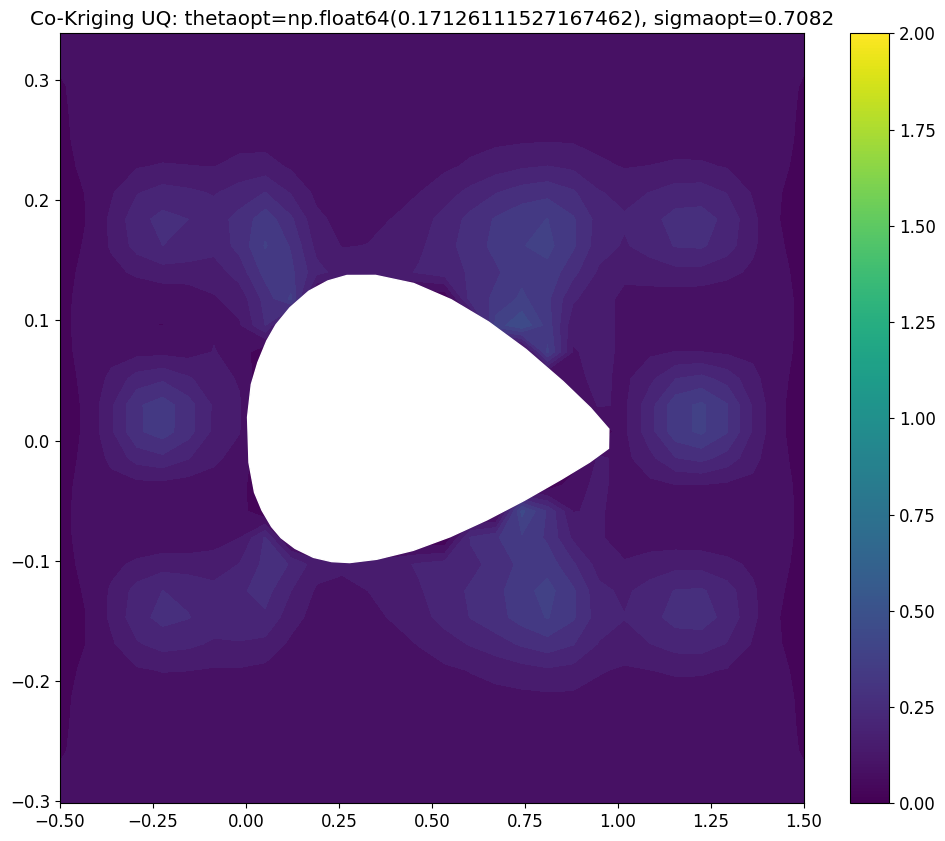

In [84]:
## Co-Kriging uncertainty in prediction.
## Generalized chi^2 distribtion. Quadratic form of two dependent gaussian vectors vx, vy. 
if UQFLAG == 1:
    CondVar = sigmaopt**2 * CondVar;
    CVxVx = np.diag(CondVar[:qout, :qout])                        # Var[Vx]
    CVxVy = np.diag(CondVar[:qout, qout:])                        # Cov[Vx, Vy]
    CVyVy = np.diag(CondVar[qout:, qout:])                        # Var[Vy]
    ChiVar = np.zeros(qout)                                       # Chi^2 params.
    for i in range(qout):
        Mu = np.array([vxhat[i],                                  # predicted Vx 
                       vyhat[i]])                                 # predicted Vy
        Cov = np.array([[CVxVx[i], CVxVy[i]],                     # Cov matrix for point prediction
                        [CVxVy[i], CVyVy[i]]])
        eigvect, eigmatrix = np.linalg.eigh(Cov)
        b = eigmatrix @ Mu
        ChiVar[i] = np.sum(2 * eigvect**2 * (1 + 2*b**2))         # A derivation can be found in https://math.stackexchange.com/a/442916
                                                                  # A paper about normal ---> generalized chi^2: https://arxiv.org/pdf/2012.14331
    plt.figure(figsize = (12,10))
    plt.cla()
    UQ = np.zeros(XX.shape[0])                                    # initializing the uncertainty array.
    UQ[~withinairfoil] = ChiVar                                   # Assigning the computed uncertainty to points outside the airfoil.
    plt.contourf(XX.reshape(30, 30), YY.reshape(30,30), 
                 2*np.sqrt(UQ).reshape(30, 30),)
                #  vmin = 0.0, vmax = 1.0)                        # Same scale colorbar
    cnorm = Normalize(vmin = 0.0, vmax = 2.0)                     # To normalize the true values and scaling them to 0.0 --> 0.2 for the colorbar
    plt.colorbar(cm.ScalarMappable(norm=cnorm), ax = plt.gca())
    plt.clim(0.0, 2.0)                                            # Same scale colorbar
    # plt.colorbar()
    # plt.clim(0.0, 0.200)                                        # Same scale colorbar
    plt.fill(XB, YB,                                              
            alpha = 1, c = 'white', label='Obstacle')
    plt.title(f'Co-Kriging UQ: {thetaopt=}, {sigmaopt=:.4f}')
    # if figsave == 1:
    #     plt.savefig(IMGPATH+'FluidCKUQ.pdf', dpi = 300, bbox_inches = 'tight', pad_inches = 0)
    plt.show()